In [1]:
import io

import pandas as pd

import requests

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00381/PRSA_data_2010.1.1-2014.12.31.csv"

response = requests.get(url)

response.raise_for_status()

csv_file = io.StringIO(response.text)

pm_df = pd.read_csv(csv_file)

   

# Combine year, month, day, and hour into a datetime index.

pm_df['datetime'] = pd.to_datetime(pm_df[['year', 'month', 'day', 'hour']])

pm_df.set_index('datetime', inplace=True)

# Handle missing values.

pm_df['pm2.5'] = pm_df['pm2.5'].ffill()

pm_df['pm2.5'] = pm_df['pm2.5'].bfill()

print(f"The dataset contains a total of {len(pm_df)} hours of data. ")

The dataset contains a total of 43824 hours of data. 


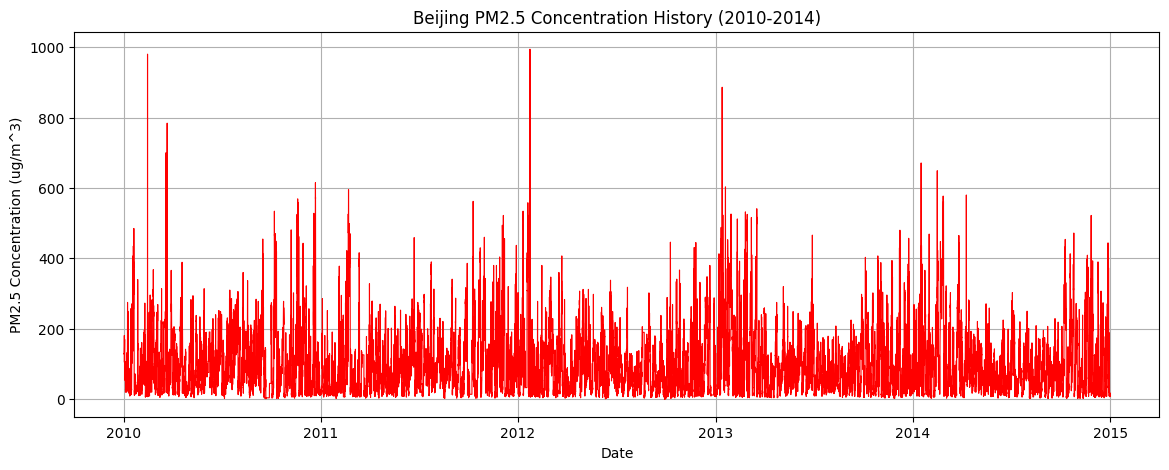

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(14, 5))

# اگر کالم کا نام بدل کر 'pollution' ہو چکا ہے تو وہ استعمال کریں، ورنہ 'pm2.5'
col_name = 'pollution' if 'pollution' in pm_df.columns else 'pm2.5'

plt.plot(pm_df.index, pm_df[col_name], color='red', linewidth=0.8)
plt.title('Beijing PM2.5 Concentration History (2010-2014)')
plt.xlabel('Date')
plt.ylabel('PM2.5 Concentration (ug/m^3)')
plt.grid(True)
plt.show()

In [3]:
import numpy as np

from sklearn.preprocessing import MinMaxScaler

 

# Normalize data.

scaler = MinMaxScaler(feature_range=(0, 1))

pm25_data = pm_df['pm2.5'].values.astype(np.float32)

scaled_data = scaler.fit_transform(pm25_data.reshape(-1, 1)).flatten()

 

# Create a time window dataset.

def create_dataset(data, seq_length):

    X, y = [], []

    for i in range(len(data) - seq_length):

        X.append(data[i:(i + seq_length)])

        y.append(data[i + seq_length])

    return np.array(X), np.array(y)

 

# Use the past 24 hours of data to predict the PM2.5 for the next hour.

seq_length = 24

X, y = create_dataset(scaled_data, seq_length)

 

# Split the dataset into a training set (80%) and a test set (20%).

train_size = int(len(X) * 0.8)

test_size = len(X) - train_size

 

X_train, X_test = X[0:train_size], X[train_size:len(X)]

y_train, y_test = y[0:train_size], y[train_size:len(y)]

In [4]:
# Convert data to the Tensor format required by MindSpore.

import mindspore as ms

from mindspore import Tensor

 

# RNN inputs require a 3D Tensor: (batch_size, seq_length, input_size).

X_train = Tensor(X_train.reshape(X_train.shape[0], X_train.shape[1], 1), ms.float32)

X_test = Tensor(X_test.reshape(X_test.shape[0], X_test.shape[1], 1), ms.float32)

 

y_train = Tensor(y_train.reshape(-1, 1), ms.float32)

y_test = Tensor(y_test.reshape(-1, 1), ms.float32)

 

print(f"X_train shape: {X_train.shape}")

print(f"y_train shape: {y_train.shape}")



X_train shape: (35040, 24, 1)
y_train shape: (35040, 1)


In [5]:
import mindspore.nn as nn

 

class AirQualityLSTM(nn.Cell):

    def __init__(self, input_size, hidden_size, num_layers, output_size):

        super(AirQualityLSTM, self).__init__()

        self.lstm = nn.LSTM(

            input_size=input_size,

            hidden_size=hidden_size,

            num_layers=num_layers,

            batch_first=True

        )

        self.fc = nn.Dense(hidden_size, output_size)

 

    def construct(self, x):

        output, _ = self.lstm(x)

        last_time_step_output = output[:, -1, :]

        prediction = self.fc(last_time_step_output)

        return prediction

 

net = AirQualityLSTM(input_size = 1, hidden_size = 64, num_layers = 2, output_size = 1)

print(net)

AirQualityLSTM(
  (lstm): LSTM(
    (rnn): _DynamicLSTMCPUGPU()
    (dropout_op): Dropout(p=0.0)
  )
  (fc): Dense(input_channels=64, output_channels=1, has_bias=True)
)


In [6]:
from mindspore.dataset import NumpySlicesDataset

from mindspore import Model, LossMonitor

 

learning_rate = 0.001

epochs = 10

batch_size = 64

 

# Create a MindSpore dataset.

train_dataset = NumpySlicesDataset({'features': X_train, 'labels': y_train}, shuffle=True).batch(batch_size=batch_size)

# Define the loss function and optimizer.

loss_fn = nn.MSELoss()

optimizer = nn.Adam(net.trainable_params(), learning_rate=learning_rate)

# Encapsulate the model.

model = Model(net, loss_fn=loss_fn, optimizer=optimizer)

 

print("Start training...")

model.train(epochs, train_dataset, callbacks=[LossMonitor(100)], dataset_sink_mode=False)

print("Training completed! ")

Start training...
epoch: 1 step: 100, loss is 0.0019913739524781704
epoch: 1 step: 200, loss is 0.0011324664810672402
epoch: 1 step: 300, loss is 0.0005409694858826697
epoch: 1 step: 400, loss is 0.0007100884104147553
epoch: 1 step: 500, loss is 0.0009645368554629385
epoch: 2 step: 52, loss is 0.0004357490979600698
epoch: 2 step: 152, loss is 0.0006281211972236633
epoch: 2 step: 252, loss is 0.00029482028912752867
epoch: 2 step: 352, loss is 0.0007685651653446257
epoch: 2 step: 452, loss is 0.00026462081586942077
epoch: 3 step: 4, loss is 0.0004914304008707404
epoch: 3 step: 104, loss is 0.0007615029462613165
epoch: 3 step: 204, loss is 0.00028621742967516184
epoch: 3 step: 304, loss is 0.000703255005646497
epoch: 3 step: 404, loss is 0.00021463555458467454
epoch: 3 step: 504, loss is 0.0007580523961223662
epoch: 4 step: 56, loss is 0.0001926494005601853
epoch: 4 step: 156, loss is 0.001589760184288025
epoch: 4 step: 256, loss is 0.0002841425593942404
epoch: 4 step: 356, loss is 0.0003

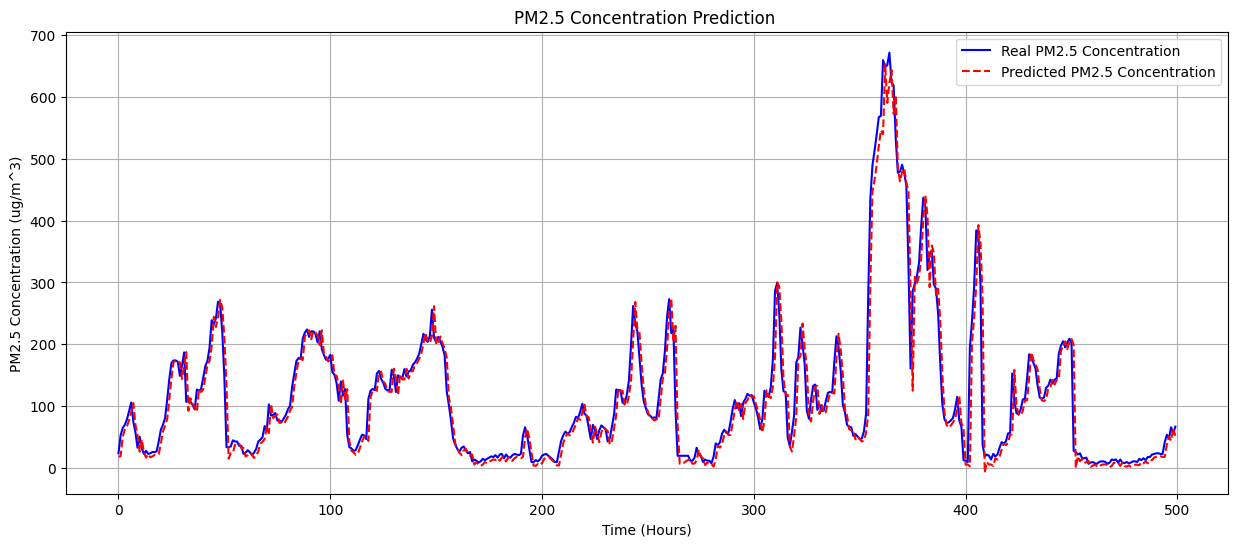

Root Mean Squared Error (RMSE): 22.05


In [7]:
# Make predictions.

predicted_scaled = model.predict(X_test)

 

# Denormalize the data to obtain the actual PM2.5 predictions.

predicted_pm25 = scaler.inverse_transform(predicted_scaled.asnumpy())

real_pm25 = scaler.inverse_transform(y_test.asnumpy())

 

# Show only the first 500 test points for clearer visualization.

plt.figure(figsize=(15, 6))

plt.plot(real_pm25[:500], color='blue', label='Real PM2.5 Concentration')

plt.plot(predicted_pm25[:500], color='red', linestyle='--', label='Predicted PM2.5 Concentration')

plt.title('PM2.5 Concentration Prediction ')

plt.xlabel('Time (Hours)')

plt.ylabel('PM2.5 Concentration (ug/m^3)')

plt.legend()

plt.grid(True)

plt.show()

 

from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(real_pm25, predicted_pm25))

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")